# MecâniQA — OAT 3: Motor de Métricas e Comprovação Visual

Fechamento para a diretoria: contrastar o **Baseline Antigo** (Naive), o **Modelo ML Inicial** (Random Forest default) e o **Modelo ML Tunado** (Grid Search).

**Métrica principal para o cliente:** MAE (litros/dia em média).


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
)
from sklearn.model_selection import TimeSeriesSplit


## Dados enriquecidos

Base com `lag_1`, `lag_7`, `mm_7` e `Manutencao_Motor` (Sprint 2), sem data leakage.


In [5]:

import pandas as pd
from sklearn.model_selection import TimeSeriesSplit

# 1. Carregar e organizar os dados
df = pd.read_csv(
    "/content/mecaniqa_dataset.csv",
    parse_dates=["Data"]
).set_index("Data").sort_index()

# 2. Criar as variáveis temporais
df["lag_1"] = df["Trocas_Oleo"].shift(1)
df["lag_7"] = df["Trocas_Oleo"].shift(7)
df["mm_7"] = df["Trocas_Oleo"].shift(1).rolling(window=7).mean()

# 3. Remover linhas sem histórico suficiente
df = df.dropna(subset=["lag_1", "lag_7", "mm_7", "Trocas_Oleo"])

# 4. Definir as variáveis de entrada e o alvo
features = ["lag_1", "lag_7", "mm_7", "Manutencao_Motor"]
X = df[features]
y = df["Trocas_Oleo"]

# 5. Configurar a validação temporal
tscv = TimeSeriesSplit(n_splits=5)

print("Formato dos dados:", df.shape)
print("Período:", df.index.min().date(), "→", df.index.max().date())
print("Variáveis:", list(X.columns))



Formato dos dados: (711, 5)
Período: 2024-01-08 → 2025-12-31
Variáveis: ['lag_1', 'lag_7', 'mm_7', 'Manutencao_Motor']


## Motor de Métricas

Rotina única: calcula **MAE**, **RMSE** e **MAPE** ao mesmo tempo. MAPE ignora dias com real = 0 (evita divisão por zero).


In [7]:
def calcular_metricas(y_real, y_pred):
    """Motor de métricas — MAE, RMSE e MAPE em uma chamada."""
    mae = mean_absolute_error(y_real, y_pred)
    rmse = mean_squared_error(y_real, y_pred) ** 0.5
    sem_zero = y_real != 0
    mape = mean_absolute_percentage_error(y_real[sem_zero], y_pred[sem_zero]) * 100
    return {"MAE": mae, "RMSE": rmse, "MAPE": mape}


def avaliar_serie(y_real, y_pred, tscv):
    """Média das métricas nos folds de teste do TimeSeriesSplit."""
    acumulado = {"MAE": [], "RMSE": [], "MAPE": []}
    for _, idx_teste in tscv.split(y_real):
        real = y_real.iloc[idx_teste]
        pred = y_pred.iloc[idx_teste]
        valido = real.notna() & pred.notna()
        m = calcular_metricas(real[valido], pred[valido])
        for k, v in m.items():
            acumulado[k].append(v)
    return {k: sum(v) / len(v) for k, v in acumulado.items()}


def avaliar_modelo(modelo, X, y, tscv):
    """Treina e avalia o modelo em cada fold temporal (sem embaralhar)."""
    acumulado = {"MAE": [], "RMSE": [], "MAPE": []}
    for treino, teste in tscv.split(X):
        modelo.fit(X.iloc[treino], y.iloc[treino])
        pred = pd.Series(modelo.predict(X.iloc[teste]), index=y.iloc[teste].index)
        m = calcular_metricas(y.iloc[teste], pred)
        for k, v in m.items():
            acumulado[k].append(v)
    return {k: sum(v) / len(v) for k, v in acumulado.items()}


## Três cenários

| Cenário | O que é |
| --- | --- |
| Baseline Antigo | Naive (`lag_1` = valor de ontem) |
| Modelo ML Inicial | `RandomForestRegressor` com hiperparâmetros default |
| Modelo ML Tunado | RF com `best_params_` do Grid Search (`07_grid_search_hiperparametros.ipynb`) |


In [12]:
# Hiperparâmetros vencedores do Grid Search (Encontro 7)
BEST_PARAMS = {
    "max_depth": 10,
    "min_samples_leaf": 4,
    "min_samples_split": 10,
    "n_estimators": 50,
}

baseline_pred = df["lag_1"]  # Naive sem data leakage
modelo_inicial = RandomForestRegressor(random_state=42, n_jobs=-1)
modelo_tunado = RandomForestRegressor(**BEST_PARAMS, random_state=42, n_jobs=-1)

boletim = pd.DataFrame(
    {
        "Baseline Antigo (Naive)": avaliar_serie(y, baseline_pred, tscv),
        "Modelo ML Inicial": avaliar_modelo(modelo_inicial, X, y, tscv),
        "Modelo ML Tunado": avaliar_modelo(modelo_tunado, X, y, tscv),
    }
).T

boletim["MAE"] = boletim["MAE"].map(lambda v: round(v, 2))
boletim["RMSE"] = boletim["RMSE"].map(lambda v: round(v, 2))
boletim["MAPE"] = boletim["MAPE"].map(lambda v: round(v, 2))

print("=== Boletim OAT 3 (média dos 5 folds TimeSeriesSplit) ===")
print(boletim.to_string())
print()
print(
    "Ganho didático (MAE, trocas de óleo/dia): "
    f"Baseline {boletim.loc['Baseline Antigo (Naive)', 'MAE']:.2f} → "
    f"Tunado {boletim.loc['Modelo ML Tunado', 'MAE']:.2f}"
)
boletim


=== Boletim OAT 3 (média dos 5 folds TimeSeriesSplit) ===
                          MAE  RMSE   MAPE
Baseline Antigo (Naive)  6.62  8.90  32.63
Modelo ML Inicial        3.76  5.86  20.92
Modelo ML Tunado         3.62  4.56  20.68

Ganho didático (MAE, trocas de óleo/dia): Baseline 6.62 → Tunado 3.62


,MAE,RMSE,MAPE
Baseline Antigo (Naive),6.62,8.90,32.63
Modelo ML Inicial,3.76,5.86,20.92
Modelo ML Tunado,3.62,4.56,20.68


## Gráfico definitivo (critério de aceite)

Último fold temporal: treino no passado, previsão no futuro. Curvas:
1. Manutenções reais (`Trocas_Oleo`)
2. Baseline Antigo (Naive)
3. Modelo ML Tunado


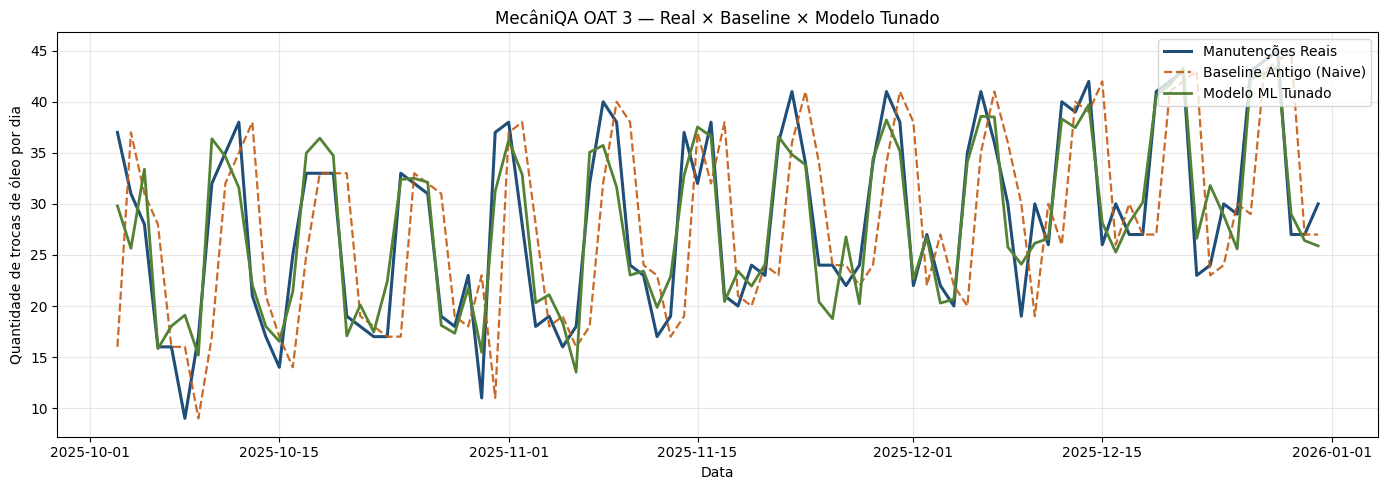

Na janela do gráfico:
  Baseline  — MAE 6.71 | RMSE 9.06 | MAPE 26.14%
  Tunado    — MAE 2.65 | RMSE 3.35 | MAPE 11.10%


In [13]:
# Último fold = janela de comprovação visual (treino passado → teste futuro)
treino_idx, teste_idx = list(tscv.split(X))[-1]

modelo_tunado.fit(X.iloc[treino_idx], y.iloc[treino_idx])
pred_tunado = pd.Series(
    modelo_tunado.predict(X.iloc[teste_idx]),
    index=y.iloc[teste_idx].index,
    name="Modelo Tunado",
)

comparacao = pd.DataFrame(
    {
        "Manutenções Reais": y.iloc[teste_idx],
        "Baseline (Naive)": baseline_pred.iloc[teste_idx],
        "Modelo Tunado": pred_tunado,
    }
).dropna()

# Janela recente para leitura clara na tela (últimos 90 dias do fold de teste)
janela = comparacao.iloc[-90:]

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(
    janela.index,
    janela["Manutenções Reais"],
    label="Manutenções Reais",
    linewidth=2.2,
    color="#1f4e79",
)
ax.plot(
    janela.index,
    janela["Baseline (Naive)"],
    label="Baseline Antigo (Naive)",
    linewidth=1.6,
    linestyle="--",
    color="#c55a11",
    alpha=0.9,
)
ax.plot(
    janela.index,
    janela["Modelo Tunado"],
    label="Modelo ML Tunado",
    linewidth=2.0,
    color="#548235",
)
ax.set_title("MecâniQA OAT 3 — Real × Baseline × Modelo Tunado")
ax.set_xlabel("Data")
ax.set_ylabel("Quantidade de trocas de óleo por dia")
ax.legend(loc="upper right")
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

# Métricas só nesta janela de plot (comprovação local)
m_base = calcular_metricas(janela["Manutenções Reais"], janela["Baseline (Naive)"])
m_tun = calcular_metricas(janela["Manutenções Reais"], janela["Modelo Tunado"])
print("Na janela do gráfico:")
print(f"  Baseline  — MAE {m_base['MAE']:.2f} | RMSE {m_base['RMSE']:.2f} | MAPE {m_base['MAPE']:.2f}%")
print(f"  Tunado    — MAE {m_tun['MAE']:.2f} | RMSE {m_tun['RMSE']:.2f} | MAPE {m_tun['MAPE']:.2f}%")


## Decisão da Equipe (brainstorm)

Para o dono da oficina, o **MAE** é a métrica mais didática, pois expressa o erro médio de previsão na unidade do negócio: trocas de óleo por dia. O **MAPE** complementa a análise com uma medida percentual do erro, enquanto o **RMSE** auxilia o time técnico a avaliar erros maiores, penalizando-os mais fortemente.